# CNN-03 · EDA das imagens de ECG

**Objetivo:** conhecer o dataset de imagens do extra (diagnóstico por imagem de ECG com CNN) antes de treinar: de onde vêm as
imagens, quantas são de verdade, como estão distribuídas entre as classes, se há problemas de qualidade e o que o modelo
pode usar como **atalho** em vez do traçado.

**Dados:** [Cardiovascular ECG Images (Kaggle)](https://www.kaggle.com/datasets/jayaprakashpondy/ecgimages/data), preparado com
`python -m cardio_visual.preparar` (uma pasta por classe em `data/images/`, uma cópia de cada imagem; ver README).

**Como ler:** os números dos textos são calculados a partir dos dados. As figuras vão para `results/figures/cnn_eda_*.png`.
A partir da seção 3, a análise usa as imagens que o modelo vai ver: 1 imagem de cada classe fica reservada para o teste
cego (`data/demo`) e não entra aqui.
**Privacidade:** as imagens trazem o ID do paciente e a data do exame impressos; nas figuras, o cabeçalho e o rodapé são cobertos.

In [1]:
import sys
from pathlib import Path

# Permite rodar o notebook fora do Docker (no Docker o PYTHONPATH já aponta para src/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from cardio.config import FIGURES_DIR
from cardio_visual.config import IMAGE_SIZE, IMAGES_DIR, TEST_SIZE, VAL_SIZE
from cardio_visual.data.loader import inspect_images, integrity_report, scan_images

%matplotlib inline
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
if not (IMAGES_DIR / "origem.csv").exists():
    raise FileNotFoundError("Prepare as imagens antes: baixe o zip do Kaggle e rode python -m cardio_visual.preparar (ver README).")

ORDEM = ["normal", "batimento_anormal", "historico_infarto", "infarto"]
NOMES = {"normal": "Normal", "batimento_anormal": "Batimento anormal",
         "historico_infarto": "Histórico de infarto", "infarto": "Infarto"}
CORES = {"normal": "#4f81bd", "batimento_anormal": "#9bbb59", "historico_infarto": "#f79646", "infarto": "#c0504d"}


def pct(x: float, casas: int = 1) -> str:
    return f"{x:.{casas}%}".replace(".", ",")


def num(x: float, casas: int = 1) -> str:
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def salvar(fig, nome: str) -> None:
    fig.savefig(FIGURES_DIR / nome, dpi=150, bbox_inches="tight")

## 1. Do zip às imagens únicas

O zip do Kaggle tem as pastas `train/` e `test/`. A preparação junta as duas e guarda **uma cópia** de cada imagem
(comparando o conteúdo pelo hash MD5). O `origem.csv` registra, para cada imagem única, os arquivos do zip de onde ela veio.

In [2]:
origem = pd.read_csv(IMAGES_DIR / "origem.csv")
origem["arquivos_test"] = origem["arquivos_originais"].str.count("test/")
origem["arquivos_train"] = origem["arquivos_originais"].str.count("train/")

por_classe = (origem.groupby("classe")
              .agg(arquivos_no_zip=("copias", "sum"), imagens_unicas=("md5", "size"),
                   arquivos_train=("arquivos_train", "sum"), arquivos_test=("arquivos_test", "sum"))
              .reindex(ORDEM))
por_classe["arquivos_por_imagem"] = (por_classe["arquivos_no_zip"] / por_classe["imagens_unicas"]).round(1)
por_classe.rename(index=NOMES)

,arquivos_no_zip,imagens_unicas,arquivos_train,arquivos_test,arquivos_por_imagem
classe,,,,,
Normal,396,142,284,112,2.8
Batimento anormal,345,233,233,112,1.5
Histórico de infarto,284,86,172,112,3.3
Infarto,351,30,239,112,11.7


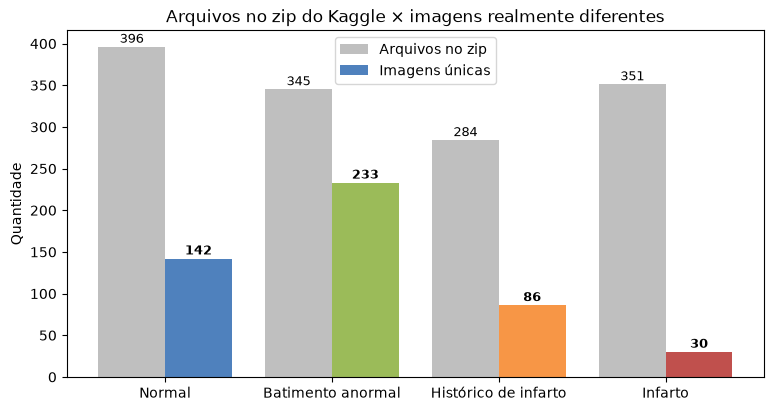

Interpretação: o zip tem 1376 arquivos, mas só 491 imagens diferentes (64,3% são cópias). Dos 448 arquivos de test/, 448 (100,0%) são cópias de imagens que também estão em train/: avaliar no test/ original mediria o modelo em imagens já vistas no treino. A classe mais repetida é «Infarto»: cada imagem aparece em 11,7 arquivos do zip, em média. Por isso usamos só as imagens únicas e fazemos a nossa própria divisão em treino, validação e teste.


In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(ORDEM))
ax.bar(x - 0.2, por_classe["arquivos_no_zip"], 0.4, label="Arquivos no zip", color="#bfbfbf")
ax.bar(x + 0.2, por_classe["imagens_unicas"], 0.4, label="Imagens únicas", color=[CORES[k] for k in ORDEM])
for i, (a, u) in enumerate(zip(por_classe["arquivos_no_zip"], por_classe["imagens_unicas"])):
    ax.text(i - 0.2, a + 5, str(a), ha="center", fontsize=9)
    ax.text(i + 0.2, u + 5, str(u), ha="center", fontsize=9, fontweight="bold")
ax.set(xticks=x, xticklabels=[NOMES[k] for k in ORDEM], ylabel="Quantidade",
       title="Arquivos no zip do Kaggle × imagens realmente diferentes")
ax.legend()
salvar(fig, "cnn_eda_duplicatas.png")
plt.show()

total_arquivos, total_unicas = int(por_classe["arquivos_no_zip"].sum()), int(por_classe["imagens_unicas"].sum())
test_total = int(origem["arquivos_test"].sum())
test_copias = int(origem.loc[origem["arquivos_train"] > 0, "arquivos_test"].sum())
pior = por_classe["arquivos_por_imagem"].idxmax()
print(f"Interpretação: o zip tem {total_arquivos} arquivos, mas só {total_unicas} imagens diferentes "
      f"({pct(1 - total_unicas / total_arquivos)} são cópias). Dos {test_total} arquivos de test/, {test_copias} "
      f"({pct(test_copias / test_total)}) são cópias de imagens que também estão em train/: avaliar no test/ original "
      f"mediria o modelo em imagens já vistas no treino. A classe mais repetida é «{NOMES[pior]}»: cada imagem "
      f"aparece em {num(por_classe.loc[pior, 'arquivos_por_imagem'])} arquivos do zip, em média. Por isso usamos só as imagens "
      f"únicas e fazemos a nossa própria divisão em treino, validação e teste.")

## 2. Balanceamento das classes (imagens únicas)

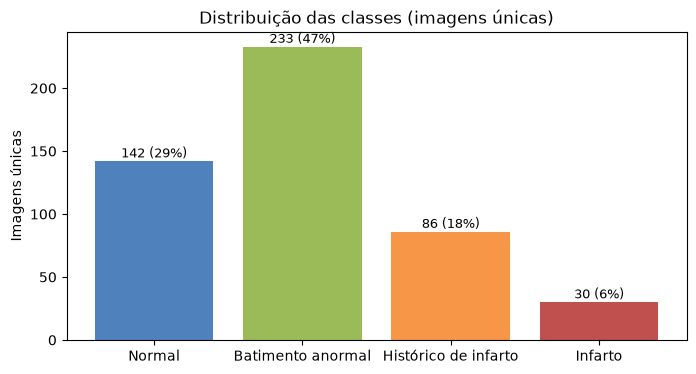

                      únicas  teste cego (reservadas)  para o modelo  validação (~15%)  teste (~15%)
classe                                                                                              
Normal                   142                        1            141                21            21
Batimento anormal        233                        1            232                35            35
Histórico de infarto      86                        1             85                13            13
Infarto                   30                        1             29                 4             4

Interpretação: as classes são desbalanceadas: «Batimento anormal» tem 233 imagens e «Infarto» só 30 (7,8 vezes menos). Uma imagem de cada classe fica reservada para o teste cego, e sobram 487 para o modelo. Com o split 70/15/15, a validação e o teste terão por volta de 4 imagens de «Infarto»: um acerto a mais ou a menos muda o recall dessa classe em ~25%. Isso pede pesos de classe no treino

In [4]:
unicas = por_classe["imagens_unicas"]
# 1 imagem de cada classe foi reservada para o teste cego (data/demo) e nunca chega ao modelo
gabarito = pd.read_csv(IMAGES_DIR.parent / "demo_gabarito.csv")
reservadas = gabarito["classe"].value_counts().reindex(ORDEM).fillna(0).astype(int)
disponiveis = unicas - reservadas
fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar([NOMES[k] for k in ORDEM], unicas, color=[CORES[k] for k in ORDEM])
for b, n in zip(barras, unicas):
    ax.text(b.get_x() + b.get_width() / 2, n + 3, f"{n} ({pct(n / unicas.sum(), 0)})", ha="center", fontsize=9)
ax.set(ylabel="Imagens únicas", title="Distribuição das classes (imagens únicas)")
salvar(fig, "cnn_eda_classes.png")
plt.show()

esperado = pd.DataFrame({"únicas": unicas, "teste cego (reservadas)": reservadas, "para o modelo": disponiveis,
                         "validação (~15%)": (disponiveis * VAL_SIZE).round().astype(int),
                         "teste (~15%)": (disponiveis * TEST_SIZE).round().astype(int)}).rename(index=NOMES)
print(esperado.to_string())
maior, menor = unicas.idxmax(), unicas.idxmin()
print(f"\nInterpretação: as classes são desbalanceadas: «{NOMES[maior]}» tem {unicas[maior]} imagens e «{NOMES[menor]}» "
      f"só {unicas[menor]} ({num(unicas[maior] / unicas[menor])} vezes menos). Uma imagem de cada classe fica reservada para "
      f"o teste cego, e sobram {int(disponiveis.sum())} para o modelo. Com o split 70/15/15, a validação e o teste "
      f"terão por volta de {esperado.loc[NOMES[menor], 'teste (~15%)']} imagens de «{NOMES[menor]}»: um acerto a mais ou a menos "
      f"muda o recall dessa classe em ~{pct(1 / max(esperado.loc[NOMES[menor], 'teste (~15%)'], 1), 0)}. Isso pede pesos de classe "
      "no treino, métricas por classe e intervalos de confiança na avaliação (CNN-06).")

## 3. Integridade: arquivos, tamanhos e quase-duplicatas

In [5]:
imagens = scan_images()
inspecionadas = inspect_images(imagens)
rel = integrity_report(inspecionadas)
print(f"Imagens: {rel['total']} | corrompidas: {len(rel['corrompidas'])} | modos de cor: {rel['modos']}")
print(f"Tamanhos (largura, altura): {rel['tamanhos']}")
print(f"Duplicatas exatas: {rel['duplicatas_exatas']} | quase-duplicatas (hash perceptual): {rel['quase_duplicatas']}")
tamanho = max(rel["tamanhos"], key=rel["tamanhos"].get)
print(f"\nInterpretação: nenhuma imagem corrompida e {'todas' if len(rel['tamanhos']) == 1 else 'quase todas'} com o mesmo "
      f"tamanho ({tamanho[0]} × {tamanho[1]} pixels, proporção {num(tamanho[0] / tamanho[1], 2)}): são impressões de ECG "
      "geradas pelo mesmo software. Depois da preparação não sobram duplicatas exatas, e o hash perceptual não acha "
      "imagens quase iguais (a mesma imagem recomprimida ou redimensionada).")

Imagens: 487 | corrompidas: 0 | modos de cor: {'RGB': 487}
Tamanhos (largura, altura): {(2213, 1572): 487}
Duplicatas exatas: 0 | quase-duplicatas (hash perceptual): 0

Interpretação: nenhuma imagem corrompida e todas com o mesmo tamanho (2213 × 1572 pixels, proporção 1,41): são impressões de ECG geradas pelo mesmo software. Depois da preparação não sobram duplicatas exatas, e o hash perceptual não acha imagens quase iguais (a mesma imagem recomprimida ou redimensionada).


## 4. Onde está o traçado

Cada imagem é um **relatório impresso**: cabeçalho com o ID do paciente e campos do exame, a grade vermelha com as 12
derivações e uma tira de ritmo, e um rodapé com filtros, frequência cardíaca, data e hora. Procuramos a moldura da grade
(pixels rosados formando linhas longas) em todas as imagens.

In [6]:
def caixa_da_grade(caminho) -> tuple[int, int, int, int] | None:
    """(x0, y0, x1, y1) da moldura da grade vermelha, pelas linhas e colunas com mais da metade dos pixels rosados."""
    a = np.asarray(Image.open(caminho).convert("RGB"), dtype=int)
    r, g, b = a[..., 0], a[..., 1], a[..., 2]
    rosa = (r > 200) & (r - g > 25) & (r - b > 25)
    linhas, colunas = np.flatnonzero(rosa.mean(axis=1) > 0.5), np.flatnonzero(rosa.mean(axis=0) > 0.5)
    if len(linhas) == 0 or len(colunas) == 0:
        return None
    return int(colunas.min()), int(linhas.min()), int(colunas.max()), int(linhas.max())


caixas = pd.DataFrame([caixa_da_grade(p) or (None,) * 4 for p in imagens["caminho"]], columns=["x0", "y0", "x1", "y1"])
encontradas = caixas.dropna()
CAIXA = tuple(int(v) for v in encontradas.median())
print(f"Moldura encontrada em {len(encontradas)} de {len(caixas)} imagens; variação entre imagens: "
      f"{int((encontradas.max() - encontradas.min()).max())} pixels")
print(f"Caixa da grade (x0, y0, x1, y1): {CAIXA}")
largura_total, altura_total = tamanho
area = (CAIXA[2] - CAIXA[0]) * (CAIXA[3] - CAIXA[1]) / (largura_total * altura_total)
print(f"\nInterpretação: a grade está na mesma posição em todas as imagens. Ela ocupa {pct(area, 0)} da folha; o resto é "
      "texto (ID do paciente, data, hora e frequência cardíaca impressos). Esses campos não são o ECG e podem virar "
      "atalho (ex.: datas ou frequências típicas de uma classe), além de serem dados pessoais. Recomendação para o "
      f"pipeline (CNN-04): recortar a caixa {CAIXA} antes de redimensionar.")


def mascarar(img: Image.Image) -> np.ndarray:
    """Cobre o cabeçalho e o rodapé (ID do paciente, data e hora) com cinza claro, para as figuras."""
    a = np.asarray(img.convert("RGB")).copy()
    a[: CAIXA[1] - 5] = 225
    a[CAIXA[3] + 5:] = 225
    return a

Moldura encontrada em 487 de 487 imagens; variação entre imagens: 0 pixels
Caixa da grade (x0, y0, x1, y1): (68, 283, 2176, 1517)

Interpretação: a grade está na mesma posição em todas as imagens. Ela ocupa 75% da folha; o resto é texto (ID do paciente, data, hora e frequência cardíaca impressos). Esses campos não são o ECG e podem virar atalho (ex.: datas ou frequências típicas de uma classe), além de serem dados pessoais. Recomendação para o pipeline (CNN-04): recortar a caixa (68, 283, 2176, 1517) antes de redimensionar.


## 5. Exemplos de cada classe

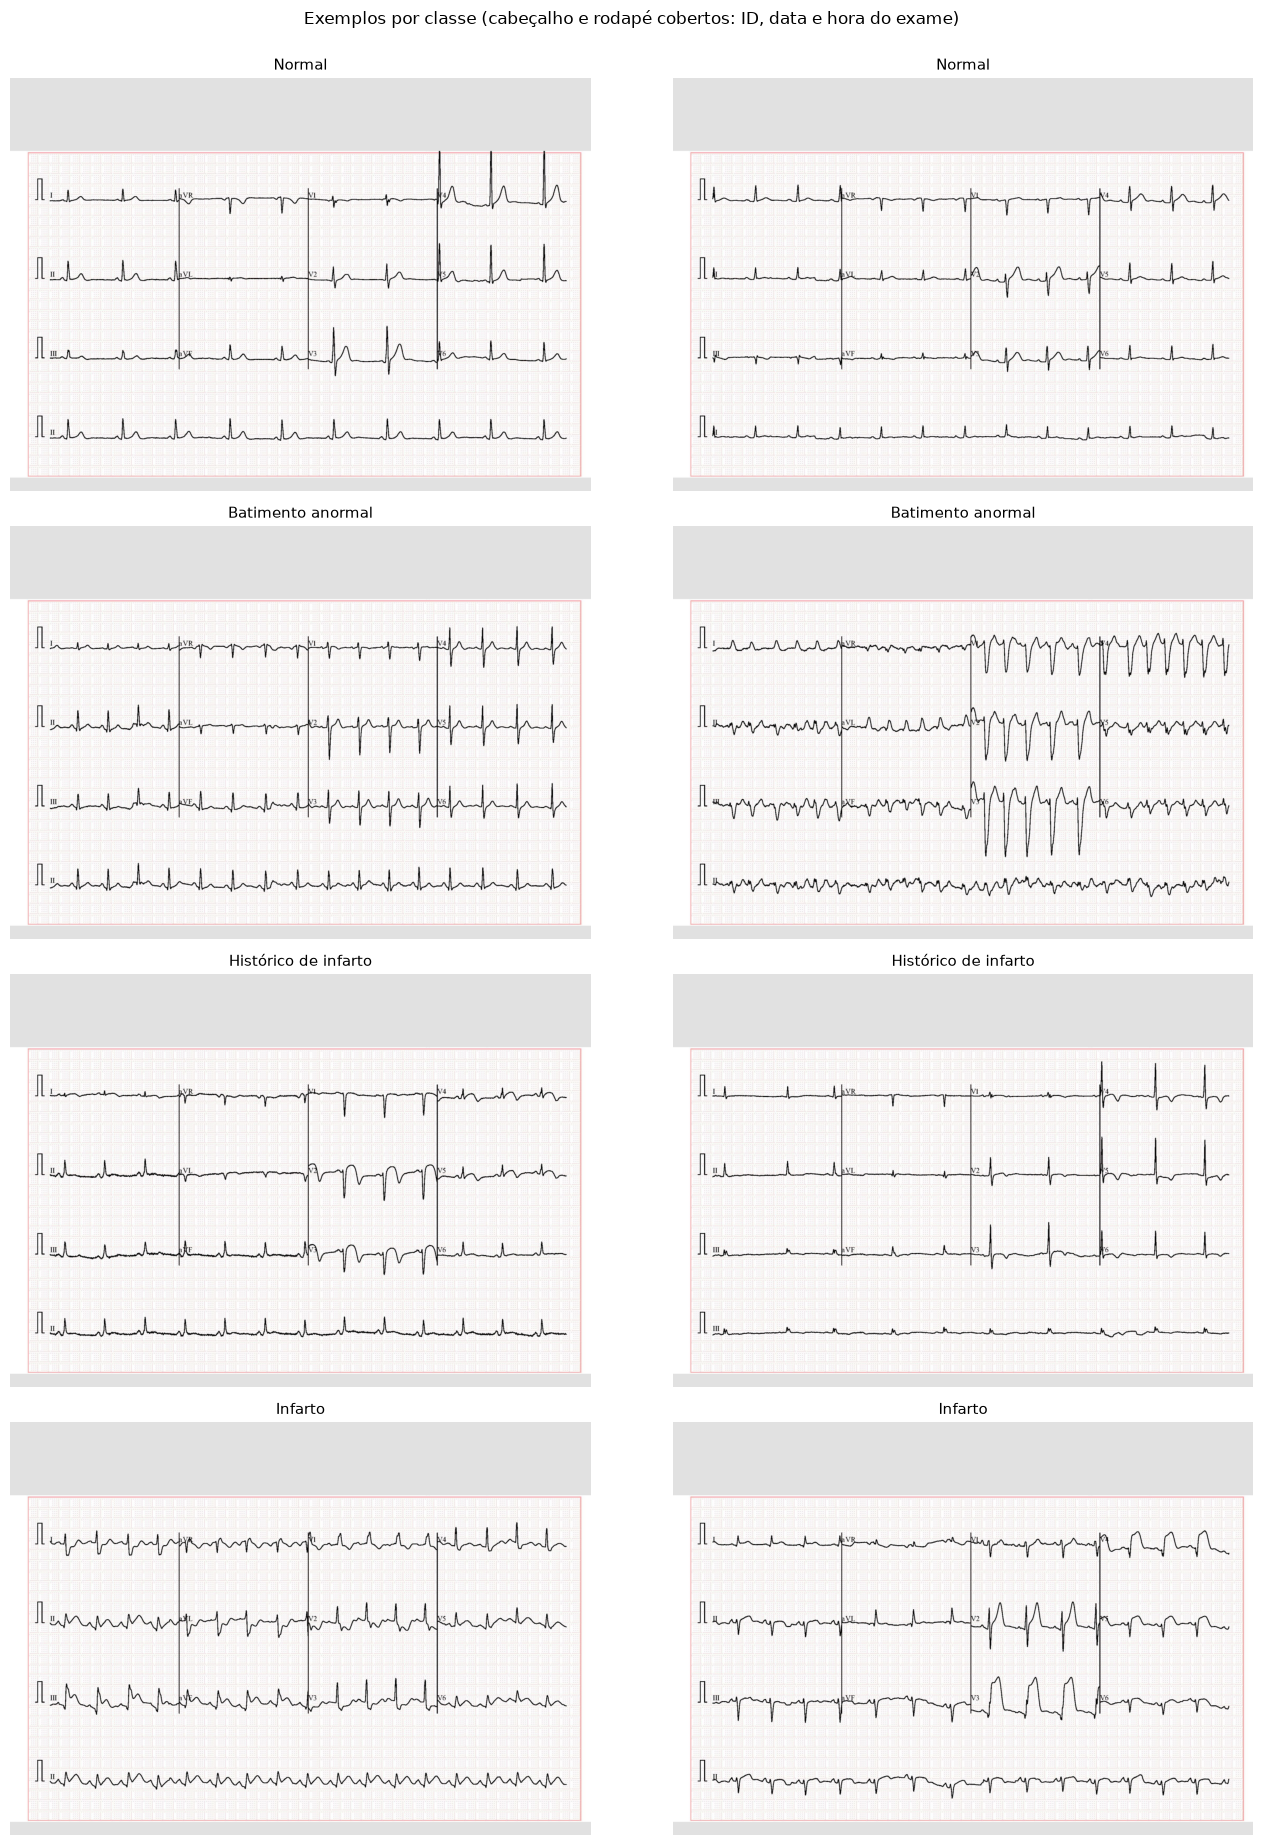

In [7]:
rng = np.random.default_rng(42)
fig, eixos = plt.subplots(len(ORDEM), 2, figsize=(14, 4.6 * len(ORDEM)))
for linha, classe in zip(eixos, ORDEM):
    escolhidas = rng.choice(imagens.loc[imagens["classe"] == classe, "caminho"].to_numpy(), 2, replace=False)
    for eixo, caminho in zip(linha, escolhidas):
        with Image.open(caminho) as img:
            coberta = Image.fromarray(mascarar(img))  # cobre na resolução original, só depois reduz
            eixo.imshow(coberta.resize((img.width // 2, img.height // 2)))
        eixo.set_title(NOMES[classe], fontsize=11)
        eixo.axis("off")
fig.suptitle("Exemplos por classe (cabeçalho e rodapé cobertos: ID, data e hora do exame)", y=1.0)
fig.tight_layout()
salvar(fig, "cnn_eda_exemplos.png")
plt.show()

**Interpretação (leitura visual):** todas as imagens seguem o mesmo formato: 12 derivações em 3 linhas × 4 colunas (I, II e III;
aVR, aVL e aVF; V1 a V6) e uma tira de ritmo longa embaixo, sobre a grade milimetrada. As diferenças entre classes estão nos
complexos (forma do QRS, segmento ST, onda T e ritmo), que ocupam uma área pequena de cada derivação. Num ECG, essas
alterações são sutis mesmo para um médico, o que já indica que o problema é difícil com poucas centenas de imagens.

## 6. Imagem média por classe: o layout difere entre as classes?

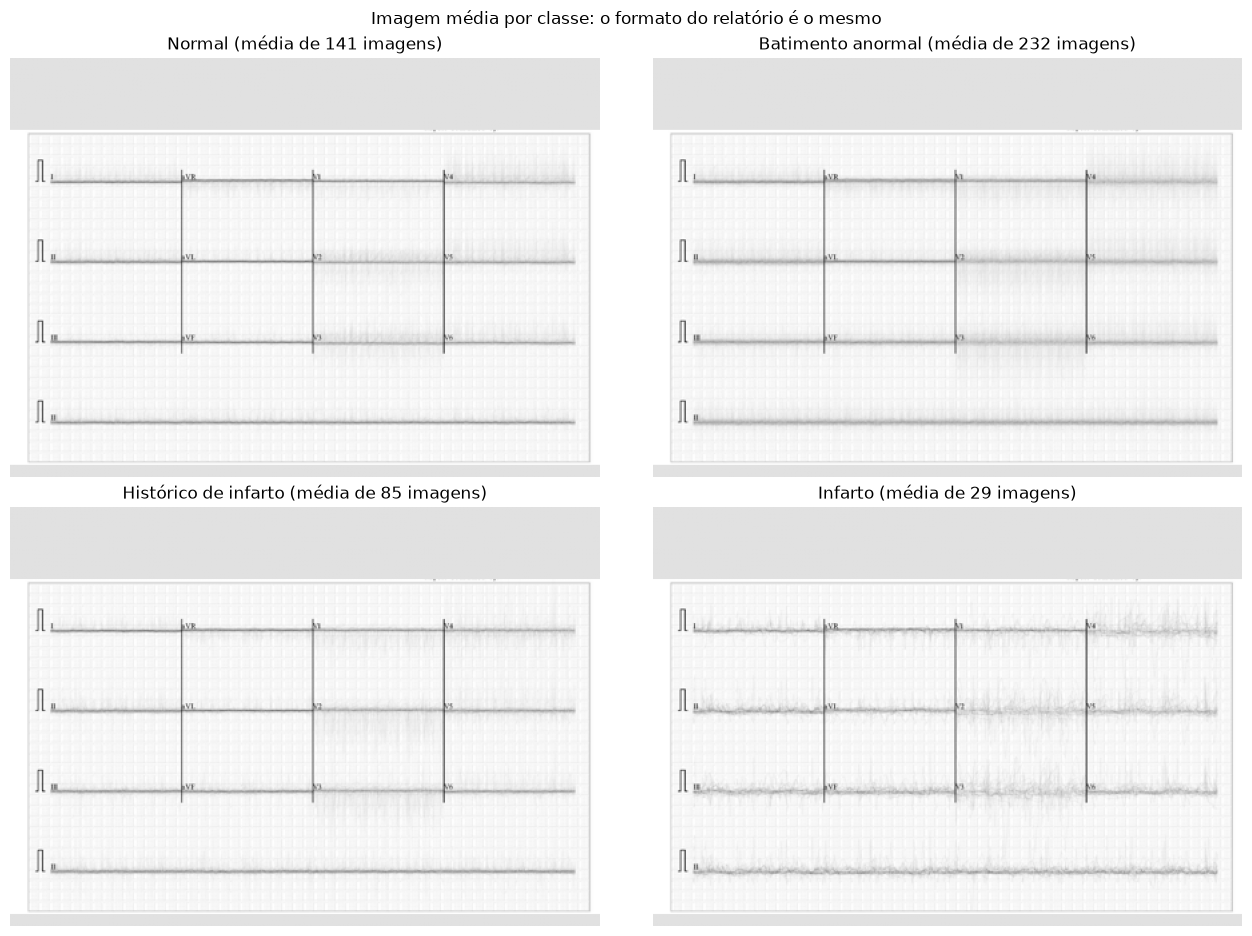

Diferença média absoluta para a média geral, na área da grade (níveis de cinza, 0 a 255): {'Normal': '1,52', 'Batimento anormal': '1,55', 'Histórico de infarto': '1,49', 'Infarto': '1,93'}

Interpretação: as médias das 4 classes são quase idênticas (diferenças de 1,5 a 1,9 níveis de cinza numa escala de 255): mesmo modelo de relatório, mesma posição das derivações e da grade. O layout não separa as classes; o que muda são os traçados, que aparecem borrados na média porque cada paciente tem batimentos em posições diferentes. A classe com menos imagens tem a média mais 'ruidosa' só por ter menos exemplos.


In [8]:
LADO_MEDIA = (442, 314)
medias = {}
for classe in ORDEM:
    soma = np.zeros(LADO_MEDIA[::-1])
    caminhos = imagens.loc[imagens["classe"] == classe, "caminho"]
    for caminho in caminhos:
        with Image.open(caminho) as img:
            soma += np.asarray(img.convert("L").resize(LADO_MEDIA), dtype=float)
    medias[classe] = soma / len(caminhos)
geral = np.mean(list(medias.values()), axis=0)
escala = LADO_MEDIA[1] / altura_total
topo, base = int(CAIXA[1] * escala) - 2, int(CAIXA[3] * escala) + 2

fig, eixos = plt.subplots(2, 2, figsize=(13, 9.5))
for eixo, classe in zip(eixos.ravel(), ORDEM):
    imagem = medias[classe].copy()
    imagem[:topo], imagem[base:] = 225, 225  # mesmo cuidado com o texto
    eixo.imshow(imagem, cmap="gray", vmin=0, vmax=255)
    eixo.set_title(f"{NOMES[classe]} (média de {int((imagens['classe'] == classe).sum())} imagens)")
    eixo.axis("off")
fig.suptitle("Imagem média por classe: o formato do relatório é o mesmo")
fig.tight_layout()
salvar(fig, "cnn_eda_media_por_classe.png")
plt.show()

diferencas = {NOMES[k]: float(np.abs(medias[k] - geral)[topo:base].mean()) for k in ORDEM}
print("Diferença média absoluta para a média geral, na área da grade (níveis de cinza, 0 a 255):",
      {k: num(v, 2) for k, v in diferencas.items()})
print(f"\nInterpretação: as médias das {len(ORDEM)} classes são quase idênticas (diferenças de "
      f"{num(min(diferencas.values()), 1)} a {num(max(diferencas.values()), 1)} níveis de cinza numa escala de 255): mesmo "
      "modelo de relatório, mesma posição das derivações e da grade. O layout não separa as classes; o que muda são os "
      "traçados, que aparecem borrados na média porque cada paciente tem batimentos em posições diferentes. A classe com "
      "menos imagens tem a média mais 'ruidosa' só por ter menos exemplos.")

## 7. Intensidade e quantidade de traçado por classe

Medido **só dentro da grade** (sem o texto): brilho médio, contraste (desvio-padrão do cinza) e a fração de pixels escuros
("tinta", ou seja, o traçado). Diferenças grandes de brilho ou contraste entre classes indicariam viés de coleta
(ex.: impressora ou scanner diferentes), um atalho que o modelo aprenderia.

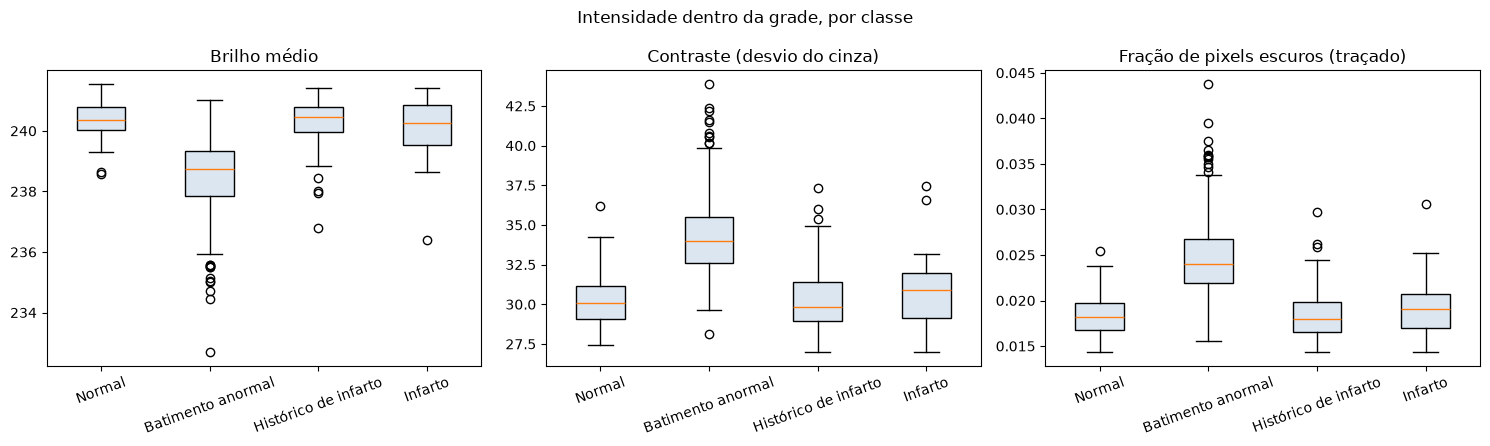

                       brilho  contraste  tinta
classe                                         
Normal                240.375     30.081  0.018
Batimento anormal     238.725     34.005  0.024
Histórico de infarto  240.470     29.809  0.018
Infarto               240.265     30.908  0.019

Interpretação: o brilho mediano varia só 1,7 níveis de cinza entre as classes (fundo branco igual), então não há sinal de impressora ou scanner diferente por classe. A classe «Batimento anormal» tem 1,32 vezes mais traçado que as outras (mediana). Isso pode ser fisiológico (mais batimentos ou complexos mais largos numa arritmia), mas também é algo que o modelo pode usar sem 'entender' o ECG: vale conferir no Grad-CAM (CNN-08) se a decisão vem dos complexos ou só da quantidade de tinta.


In [9]:
medidas = []
for caminho, classe in zip(imagens["caminho"], imagens["classe"]):
    with Image.open(caminho) as img:
        a = np.asarray(img.convert("L").crop(CAIXA).resize((527, 308)), dtype=float)
    medidas.append({"classe": classe, "brilho": a.mean(), "contraste": a.std(), "tinta": (a < 100).mean()})
medidas = pd.DataFrame(medidas)

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))
for eixo, (coluna, titulo) in zip(eixos, [("brilho", "Brilho médio"), ("contraste", "Contraste (desvio do cinza)"),
                                           ("tinta", "Fração de pixels escuros (traçado)")]):
    eixo.boxplot([medidas.loc[medidas["classe"] == k, coluna] for k in ORDEM], tick_labels=[NOMES[k] for k in ORDEM],
                 patch_artist=True, boxprops={"facecolor": "#dce6f1"})
    eixo.set_title(titulo)
    eixo.tick_params(axis="x", rotation=20)
fig.suptitle("Intensidade dentro da grade, por classe")
fig.tight_layout()
salvar(fig, "cnn_eda_intensidade.png")
plt.show()

medianas = medidas.groupby("classe")[["brilho", "contraste", "tinta"]].median().reindex(ORDEM)
print(medianas.rename(index=NOMES).round(3).to_string())
faixa_brilho = medianas["brilho"].max() - medianas["brilho"].min()
mais_tinta = medianas["tinta"].idxmax()
razao_tinta = medianas["tinta"].max() / medianas["tinta"].drop(mais_tinta).median()
print(f"\nInterpretação: o brilho mediano varia só {num(faixa_brilho, 1)} níveis de cinza entre as classes (fundo branco igual), "
      "então não há sinal de impressora ou scanner diferente por classe. A classe «" + NOMES[mais_tinta] +
      f"» tem {num(razao_tinta, 2)} vezes mais traçado que as outras (mediana). Isso pode ser fisiológico (mais batimentos "
      "ou complexos mais largos numa arritmia), mas também é algo que o modelo pode usar sem 'entender' o ECG: vale "
      "conferir no Grad-CAM (CNN-08) se a decisão vem dos complexos ou só da quantidade de tinta.")

## 8. Resolução: o que sobra do ECG em 224 × 224 pixels?

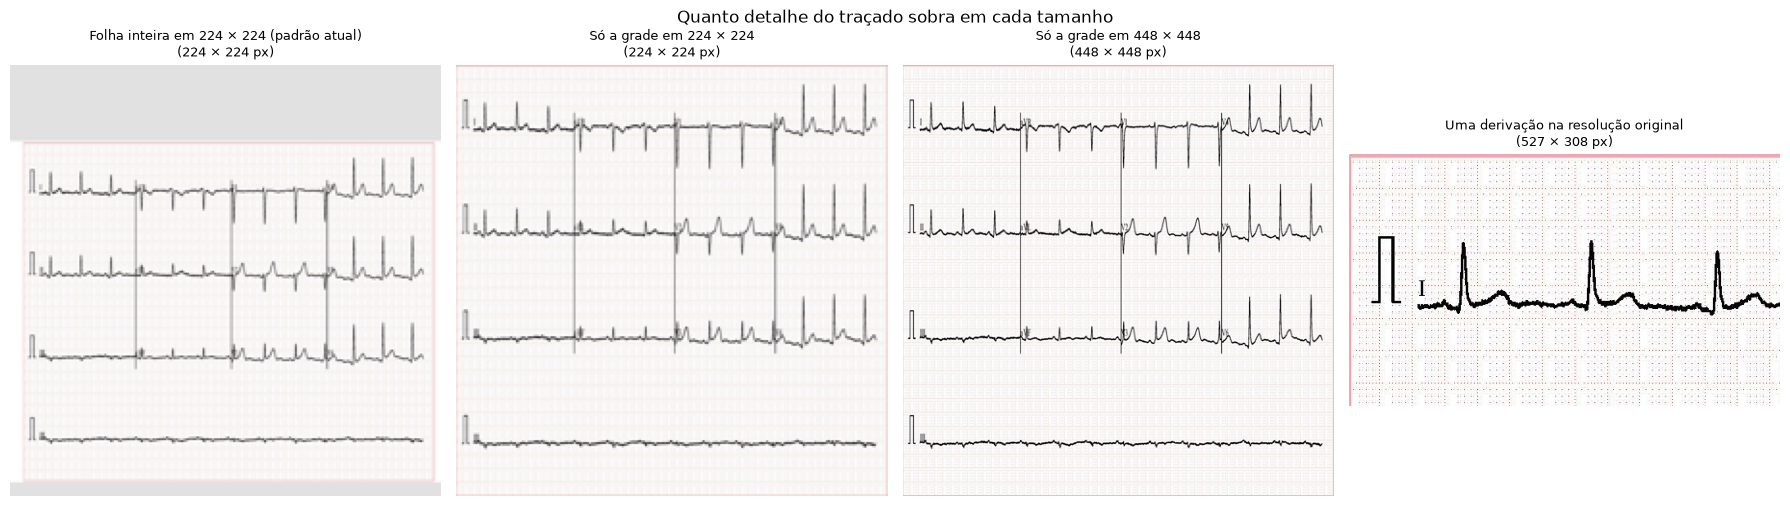

Interpretação: cada derivação tem 527 pixels de largura na imagem original. Em 224 × 224, a folha inteira deixa cada derivação com ~53 pixels, e recortar a grade sobe para ~56: o recorte tira o texto, mas ganha pouco detalhe. O tamanho de entrada pesa mais: em 448 × 448 cada derivação fica com ~112 pixels e o segmento ST e a onda T ficam bem mais nítidos. Além disso, o redimensionamento para um quadrado achata a imagem (a grade tem proporção 1,71). Recomendação: testar 224 e 448 (ou um retângulo) no treino (CNN-07).


In [10]:
exemplo = imagens.loc[imagens["classe"] == "normal", "caminho"].iloc[0]
with Image.open(exemplo) as img:
    original = img.convert("RGB")
grade = original.crop(CAIXA)
largura_derivacao = (CAIXA[2] - CAIXA[0]) / 4  # 4 colunas de derivações
paineis = [
    ("Folha inteira em 224 × 224 (padrão atual)", Image.fromarray(mascarar(original)).resize((IMAGE_SIZE, IMAGE_SIZE))),
    ("Só a grade em 224 × 224", grade.resize((IMAGE_SIZE, IMAGE_SIZE))),
    ("Só a grade em 448 × 448", grade.resize((448, 448))),
    ("Uma derivação na resolução original", grade.crop((0, 0, int(largura_derivacao), int(grade.height / 4)))),
]
fig, eixos = plt.subplots(1, 4, figsize=(18, 4.8))
for eixo, (titulo, img) in zip(eixos, paineis):
    eixo.imshow(img)
    eixo.set_title(f"{titulo}\n({img.width} × {img.height} px)", fontsize=9)
    eixo.axis("off")
fig.tight_layout()
fig.suptitle("Quanto detalhe do traçado sobra em cada tamanho", y=1.06)
salvar(fig, "cnn_eda_resolucao.png")
plt.show()

px_folha = IMAGE_SIZE * largura_derivacao / largura_total
px_grade = IMAGE_SIZE * largura_derivacao / (CAIXA[2] - CAIXA[0])
print(f"Interpretação: cada derivação tem {int(largura_derivacao)} pixels de largura na imagem original. Em {IMAGE_SIZE} × "
      f"{IMAGE_SIZE}, a folha inteira deixa cada derivação com ~{int(px_folha)} pixels, e recortar a grade sobe para "
      f"~{int(px_grade)}: o recorte tira o texto, mas ganha pouco detalhe. O tamanho de entrada pesa mais: em 448 × 448 cada "
      f"derivação fica com ~{int(2 * px_grade)} pixels e o segmento ST e a onda T ficam bem mais nítidos. Além disso, o "
      f"redimensionamento para um quadrado achata a imagem (a grade tem proporção {num((CAIXA[2] - CAIXA[0]) / (CAIXA[3] - CAIXA[1]), 2)}). "
      "Recomendação: testar 224 e 448 (ou um retângulo) no treino (CNN-07).")

## 9. Quatro classes ou binário? (decisão D2)

In [11]:
binario = pd.Series({"Normal": int(disponiveis["normal"]),
                     "Alterado (as outras 3 classes)": int(disponiveis.drop("normal").sum())})
tabela_d2 = pd.DataFrame({
    "classes": ["4 classes", "binário"],
    "menor classe (imagens)": [int(disponiveis.min()), int(binario.min())],
    "menor classe no teste (~15%)": [int(round(disponiveis.min() * TEST_SIZE)), int(round(binario.min() * TEST_SIZE))],
})
print(binario.to_string())
print()
print(tabela_d2.to_string(index=False))
print(f"\nInterpretação: com 4 classes, a menor («{NOMES[menor]}») fica com ~{tabela_d2.iloc[0, 2]} imagens no teste; no binário "
      f"(normal × alterado), a menor classe tem ~{tabela_d2.iloc[1, 2]}. O binário dá métricas bem mais estáveis, mas perde a "
      "distinção clínica entre infarto, histórico de infarto e arritmia. Decisão tomada: as 4 classes são o resultado "
      "principal (com intervalos de confiança e o aviso sobre o infarto), e o binário é reportado junto na avaliação final.")

Normal                            141
Alterado (as outras 3 classes)    346

  classes  menor classe (imagens)  menor classe no teste (~15%)
4 classes                      29                             4
  binário                     141                            21

Interpretação: com 4 classes, a menor («Infarto») fica com ~4 imagens no teste; no binário (normal × alterado), a menor classe tem ~21. O binário dá métricas bem mais estáveis, mas perde a distinção clínica entre infarto, histórico de infarto e arritmia. Decisão tomada: as 4 classes são o resultado principal (com intervalos de confiança e o aviso sobre o infarto), e o binário é reportado junto na avaliação final.


## 10. Resumo

In [12]:
print(f"""1. O zip do Kaggle tem {total_arquivos} arquivos, mas só {total_unicas} imagens diferentes; o test/ original é cópia do train/.
   Usamos só as imagens únicas, reservamos 1 por classe para o teste cego e dividimos o resto em 70/15/15 (SEED = 42).
2. Classes desbalanceadas: {', '.join(f'{NOMES[k]} {int(unicas[k])}' for k in ORDEM)}. A classe «{NOMES[menor]}» terá
   ~{int(round(disponiveis[menor] * TEST_SIZE))} imagens no teste: pesos de classe, métricas por classe e intervalos de confiança.
3. Sem arquivos corrompidos nem quase-duplicatas; todas as imagens têm {tamanho[0]} × {tamanho[1]} px e o mesmo layout.
4. As imagens são relatórios impressos com ID do paciente, data, hora e frequência cardíaca: recortar a grade {CAIXA}
   antes de redimensionar (CNN-04) e nunca publicar figuras sem cobrir esses campos.
5. Brilho e contraste são iguais entre as classes (sem sinal de viés de aparelho); «{NOMES[mais_tinta]}» tem mais traçado,
   o que precisa ser conferido no Grad-CAM.
6. Em {IMAGE_SIZE} px cada derivação fica com ~{int(px_grade)} px: testar entradas maiores (448) no treino.
7. Sem giro horizontal ou vertical no aumento de dados: inverter um ECG cria um traçado que não existe.
8. Decisão D2: 4 classes como resultado principal e o binário normal × alterado reportado junto (mais estável).""")

1. O zip do Kaggle tem 1376 arquivos, mas só 491 imagens diferentes; o test/ original é cópia do train/.
   Usamos só as imagens únicas, reservamos 1 por classe para o teste cego e dividimos o resto em 70/15/15 (SEED = 42).
2. Classes desbalanceadas: Normal 142, Batimento anormal 233, Histórico de infarto 86, Infarto 30. A classe «Infarto» terá
   ~4 imagens no teste: pesos de classe, métricas por classe e intervalos de confiança.
3. Sem arquivos corrompidos nem quase-duplicatas; todas as imagens têm 2213 × 1572 px e o mesmo layout.
4. As imagens são relatórios impressos com ID do paciente, data, hora e frequência cardíaca: recortar a grade (68, 283, 2176, 1517)
   antes de redimensionar (CNN-04) e nunca publicar figuras sem cobrir esses campos.
5. Brilho e contraste são iguais entre as classes (sem sinal de viés de aparelho); «Batimento anormal» tem mais traçado,
   o que precisa ser conferido no Grad-CAM.
6. Em 224 px cada derivação fica com ~56 px: testar entradas maiores (448) no t